# EV Battery Failure Prediction Using SMOTE

### The EV Battery Failure Predictor is a machine learning project designed to predict potential electric vehicle battery failures using vehicle, battery, charging, driving, environmental, and maintenance data.
### The project uses a dataset containing 200,000 records and 70 columns, with battery_failure as the target variable for binary classification.
### Data preprocessing techniques, including missing-value imputation, feature transformation, and SMOTE-based class balancing, are applied to improve model training.
### Four machine learning algorithms—Logistic Regression, Decision Tree, Random Forest, and XGBoost—are evaluated using multiple performance metrics.
### XGBoost is selected as the final model, achieving 96.52% accuracy and a 0.9885 ROC-AUC score in the reported evaluation.

## 🚀 Key Features

### 🔋 Predicts electric vehicle battery failure using multiple battery health and vehicle-related features.

### 🧹 Handles missing values and prepares numerical and categorical data for machine learning.

### ⚖️ Applies SMOTE to balance the target classes in the training dataset.

### 📊 Evaluates models using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

### 🤖 Sation.ves the trained XGBoost model using Joblib for integration with a Streamlit-based prediction application

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sarveshchhetri/ev-battery-failure-prediction-dataset-200k/data_dictionary.csv
/kaggle/input/datasets/sarveshchhetri/ev-battery-failure-prediction-dataset-200k/feature_descriptions.md
/kaggle/input/datasets/sarveshchhetri/ev-battery-failure-prediction-dataset-200k/ev_battery_failure_dataset.csv


## Importing Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r'/kaggle/input/datasets/sarveshchhetri/ev-battery-failure-prediction-dataset-200k/ev_battery_failure_dataset.csv'
)
df.head(10)

,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0
5,EV100005,MG,ZS EV,SUV,2018.0,Samsung SDI,LFP,74.97,AWD,156939.0,...,0.0,1.0,0.0,49.2,27.7,70.7,49.6,100.0,3258.0,0
6,EV100006,Nissan,Ariya,SUV,2019.0,BYD Battery,NMC,NaN,FWD,185719.0,...,0.0,5.0,0.0,52.9,NaN,48.8,2.7,83.4,784.0,0
7,EV100007,Nissan,Ariya,SUV,2016.0,CATL,NMC,92.36,AWD,110334.0,...,5.0,3.0,2.0,73.3,45.0,44.1,18.2,56.3,1018.0,0
8,EV100008,BYD,Atto 3,Crossover,2016.0,SK On,NMC,77.77,FWD,107016.0,...,1.0,0.0,0.0,2.2,48.3,64.9,77.2,0.3,1184.0,0
9,EV100009,Audi,e-tron,SUV,2024.0,Northvolt,NMC,98.53,AWD,7051.0,...,1.0,3.0,0.0,NaN,0.0,64.0,91.5,45.0,1458.0,0


## Data Preprocessing

In [4]:
df.shape

(200000, 70)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  object 
 1   vehicle_brand                    193564 non-null  object 
 2   vehicle_model                    191796 non-null  object 
 3   vehicle_type                     193568 non-null  object 
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  object 
 6   battery_chemistry                192786 non-null  object 
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  object 
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  object 
 12  ba

In [6]:
df.describe()

,manufacturing_year,battery_capacity_kwh,odometer_km,vehicle_age_years,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
count,190171.000000,193097.000000,191334.000000,192317.000000,192348.000000,191018.000000,190364.000000,191687.000000,190435.000000,190602.000000,...,190326.000000,190948.000000,192400.000000,192691.000000,191635.000000,193671.000000,192814.000000,193190.000000,191026.000000,200000.000000
mean,2019.501333,76.236405,102822.193327,6.495245,296.383934,87.381787,54.847079,38.290397,87.297020,3.288515,...,1.331032,2.024745,0.494595,35.179580,29.912538,63.538378,50.989061,40.948318,1859.485986,0.099605
std,2.873497,21.302330,87965.819977,2.878180,282.614453,12.540742,21.450372,12.754524,12.527256,0.246766,...,1.265969,1.579874,0.729369,21.789144,28.011328,13.764340,27.815242,29.848473,1834.356925,0.299473
min,2015.000000,25.000000,500.000000,1.370000,1.000000,21.420000,2.000000,5.000000,21.800000,2.048500,...,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000
25%,2017.000000,60.980000,36128.000000,4.000000,95.000000,80.990000,40.070000,29.600000,80.910000,3.106025,...,0.000000,1.000000,0.000000,19.300000,6.900000,53.900000,30.600000,15.500000,891.000000,0.000000
50%,2020.000000,75.350000,78919.000000,6.340000,218.000000,91.120000,54.940000,38.280000,91.050000,3.355800,...,1.000000,2.000000,0.000000,33.200000,22.600000,61.400000,53.500000,38.900000,1245.000000,0.000000
75%,2022.000000,89.990000,146010.750000,9.000000,412.000000,97.430000,69.780000,46.910000,97.330000,3.463900,...,2.000000,3.000000,1.000000,48.500000,45.100000,74.000000,72.800000,63.000000,3085.000000,0.000000
max,2024.000000,149.010000,450000.000000,11.550000,3369.000000,99.800000,100.000000,92.030000,100.000000,3.853000,...,10.000000,13.000000,7.000000,100.000000,100.000000,100.000000,100.000000,100.000000,15474.000000,1.000000


In [7]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows',None)

print(df.isnull().sum())

vehicle_id                            0
vehicle_brand                      6436
vehicle_model                      8204
vehicle_type                       6432
manufacturing_year                 9829
battery_manufacturer               6188
battery_chemistry                  7214
battery_capacity_kwh               6903
drive_type                         7268
odometer_km                        8666
vehicle_age_years                  7683
fleet_or_private                   8950
battery_serial                        0
cycle_count                        7652
battery_health_percent             8982
state_of_charge                    9636
depth_of_discharge                 8313
state_of_health                    9565
cell_voltage_avg                   9398
cell_voltage_std                   8563
pack_voltage                       6175
cell_temperature_avg               7683
cell_temperature_max               9450
internal_resistance                7975
charge_efficiency                  9305


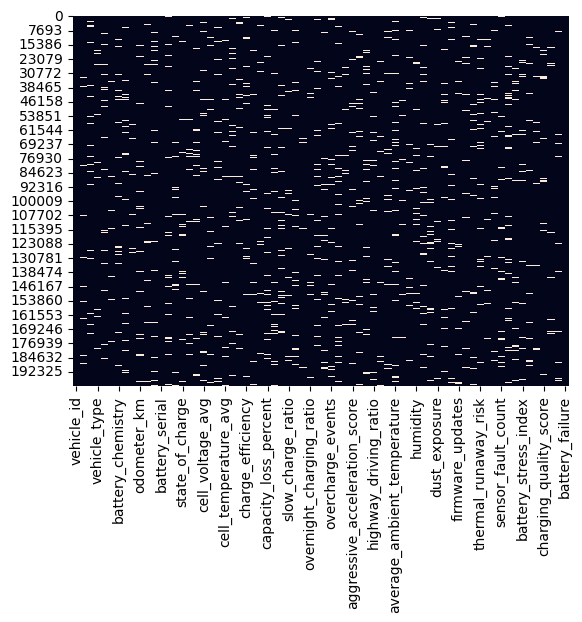

In [8]:
sns.heatmap(df.isnull(),cbar=False)
plt.show()

## Data Cleaning

In [9]:
categorical_cols = df.select_dtypes(include=['object']).columns
print(categorical_cols)

Index(['vehicle_id', 'vehicle_brand', 'vehicle_model', 'vehicle_type',
       'battery_manufacturer', 'battery_chemistry', 'drive_type',
       'fleet_or_private', 'battery_serial', 'terrain_type'],
      dtype='object')


In [10]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns
print(numerical_cols)

Index(['manufacturing_year', 'battery_capacity_kwh', 'odometer_km',
       'vehicle_age_years', 'cycle_count', 'battery_health_percent',
       'state_of_charge', 'depth_of_discharge', 'state_of_health',
       'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage',
       'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance',
       'charge_efficiency', 'discharge_efficiency', 'remaining_capacity',
       'capacity_loss_percent', 'charging_cycles_last_month',
       'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw',
       'average_charging_time', 'overnight_charging_ratio',
       'home_charging_ratio', 'charging_interruptions', 'overcharge_events',
       'average_speed', 'average_trip_distance',
       'aggressive_acceleration_score', 'hard_braking_score',
       'regenerative_braking_usage', 'highway_driving_ratio',
       'city_driving_ratio', 'daily_distance', 'average_ambient_temperature',
       'maximum_temperature', 'minimum_temperature', 'h

In [11]:
for col in categorical_cols:
  df[col] = df[col].fillna(df[col].mode()[0])

for col in numerical_cols:
  df[col] = df[col].fillna(df[col].mean().round(2))

In [12]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows',None)

print(df.isnull().sum())

vehicle_id                         0
vehicle_brand                      0
vehicle_model                      0
vehicle_type                       0
manufacturing_year                 0
battery_manufacturer               0
battery_chemistry                  0
battery_capacity_kwh               0
drive_type                         0
odometer_km                        0
vehicle_age_years                  0
fleet_or_private                   0
battery_serial                     0
cycle_count                        0
battery_health_percent             0
state_of_charge                    0
depth_of_discharge                 0
state_of_health                    0
cell_voltage_avg                   0
cell_voltage_std                   0
pack_voltage                       0
cell_temperature_avg               0
cell_temperature_max               0
internal_resistance                0
charge_efficiency                  0
discharge_efficiency               0
remaining_capacity                 0
c

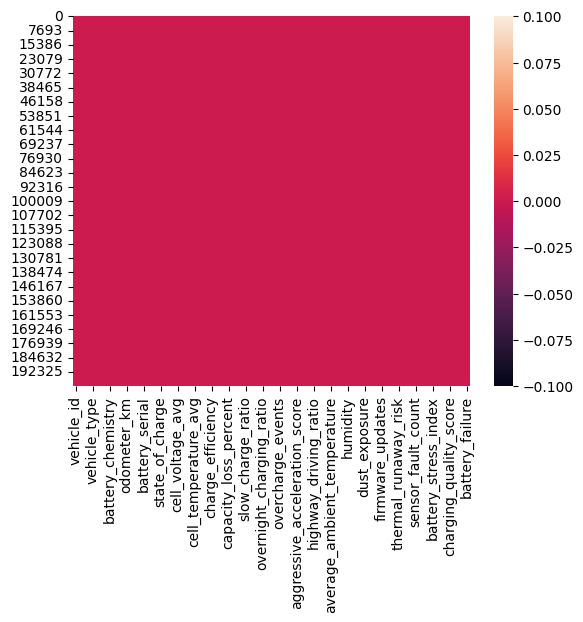

In [13]:
sns.heatmap(df.isnull())
plt.show()

In [14]:
df.head(20)

,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,battery_serial,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,cell_voltage_std,pack_voltage,cell_temperature_avg,cell_temperature_max,internal_resistance,charge_efficiency,discharge_efficiency,remaining_capacity,capacity_loss_percent,charging_cycles_last_month,fast_charge_ratio,slow_charge_ratio,average_charge_power_kw,average_charging_time,overnight_charging_ratio,home_charging_ratio,charging_interruptions,overcharge_events,average_speed,average_trip_distance,aggressive_acceleration_score,hard_braking_score,regenerative_braking_usage,highway_driving_ratio,city_driving_ratio,daily_distance,average_ambient_temperature,maximum_temperature,minimum_temperature,humidity,altitude,terrain_type,dust_exposure,last_service_days,cooling_system_health,firmware_updates,previous_faults,maintenance_score,thermal_runaway_risk,voltage_imbalance,temperature_variance,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.00,6.94,Private,BAT-91869505,250.00,73.61,85.23,26.34,72.93,3.2900,0.01829,934.42,-15.66,-10.04,0.6585,94.63,80.08,60.76,26.39,4.0,0.206,0.797,25.46,212.2,0.543,0.675,0.0,2.0,58.0,38.70,0.00,7.00,69.4,0.352,0.676,50.6,-14.30,-5.90,-21.50,100.00,400.20,Flat,20.4,159.00,79.30,2.0,0.0,94.8,48.70,15.30,5.28,2.0,3.0,0.0,0.00,53.50,66.0,65.20,0.00,401.00,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NMC,64.17,AWD,113600.00,7.79,Private,BAT-67968204,256.00,85.77,49.12,44.83,86.71,3.3658,0.01518,841.46,21.67,34.30,0.5206,95.16,94.95,55.04,14.23,3.0,0.417,0.543,55.83,68.5,0.340,0.708,0.0,2.0,30.7,29.40,36.30,33.10,80.7,0.353,0.661,50.6,26.40,44.60,18.80,72.90,702.70,Hilly,15.7,193.00,73.30,3.0,0.0,100.0,48.60,9.42,7.19,0.0,3.0,0.0,51.00,38.80,67.8,46.30,40.90,1094.00,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.00,7.85,Fleet,BAT-82263437,556.00,72.37,54.85,33.65,72.17,3.4152,0.02000,853.81,16.83,31.37,0.6135,92.21,88.87,65.80,27.63,7.0,0.624,0.379,55.38,120.5,0.416,0.449,0.0,2.0,60.5,40.00,27.60,9.80,71.0,0.374,0.623,101.3,9.50,13.00,2.40,57.80,687.40,Flat,22.9,193.00,73.80,3.0,1.0,72.2,53.20,18.86,20.75,4.0,1.0,0.0,36.20,66.10,48.6,0.00,6.50,645.00,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.00,6.50,Private,BAT-92487292,353.00,85.11,54.32,37.73,87.30,3.4202,0.01518,739.43,-1.10,6.25,0.4144,94.26,84.69,40.30,14.89,10.0,0.417,0.559,39.19,83.3,0.336,0.760,0.0,0.0,65.6,29.90,12.80,10.10,68.2,0.379,0.599,58.2,-4.20,2.00,-22.50,47.30,752.20,Hilly,59.0,60.00,88.30,0.0,0.0,95.4,53.60,12.99,9.04,0.0,3.0,1.0,23.40,32.50,58.2,50.99,40.95,867.00,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.00,11.13,Private,BAT-99314176,287.00,87.40,62.73,65.29,86.17,3.4556,0.02111,863.90,29.71,31.20,0.5663,96.60,93.78,59.47,12.60,5.0,0.250,0.755,44.07,118.2,0.454,0.586,0.0,0.0,61.6,8.10,61.00,35.40,34.2,0.000,1.000,27.5,17.98,29.80,10.30,30.60,283.60,Coastal,33.9,217.35,48.20,19.0,3.0,100.0,62.10,25.29,10.55,3.0,2.0,1.0,51.20,45.40,51.0,50.99,100.00,1090.00,0
5,EV100005,MG,ZS EV,SUV,2018.0,Samsung SDI,LFP,74.97,AWD,156939.00,8.06,Private,BAT-23606528,483.00,93.80,28.97,40.14,91.07,2.8677,0.01412,716.92,32.04,42.23,0.6265,95.66,96.41,70.32,6.20,6.0,0.529,0.475,59.89,92.5,0.149,0.479,0.0,0.0,60.6,29.40,70.80,40.00,34.9,0.639,0.344,67.1,24.30,28.20,17.80,69.10,124.80,Hilly,32.0,308.00,67.00,7.0,1.0,86.0,23.10,15.12,17.89,0.0,1.0,0.0,49.20,27.70,70.7,49.60,100.00,3258.00,0
6,EV100006,Nissan,Ariya,SUV,2019.0,BYD Battery,NMC,76.24,FWD,185719.00,6.91,Fleet,BAT-63354146,428.00,76.96,52.06,45.85,80.22,3.4145,0.01689,853.62,26.07,36.90,0.5715,92.

## Dropping columns which are not useful

In [15]:
dropped_cols = ['vehicle_id','battery_serial','vehicle_model']

df = df.drop(columns=dropped_cols)

## Data Visualization

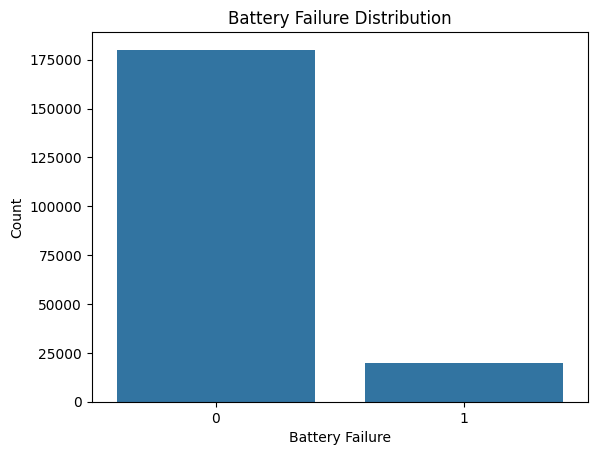

In [16]:
sns.countplot(data=df,x='battery_failure')
plt.title("Battery Failure Distribution")
plt.xlabel('Battery Failure')
plt.ylabel('Count')
plt.show()

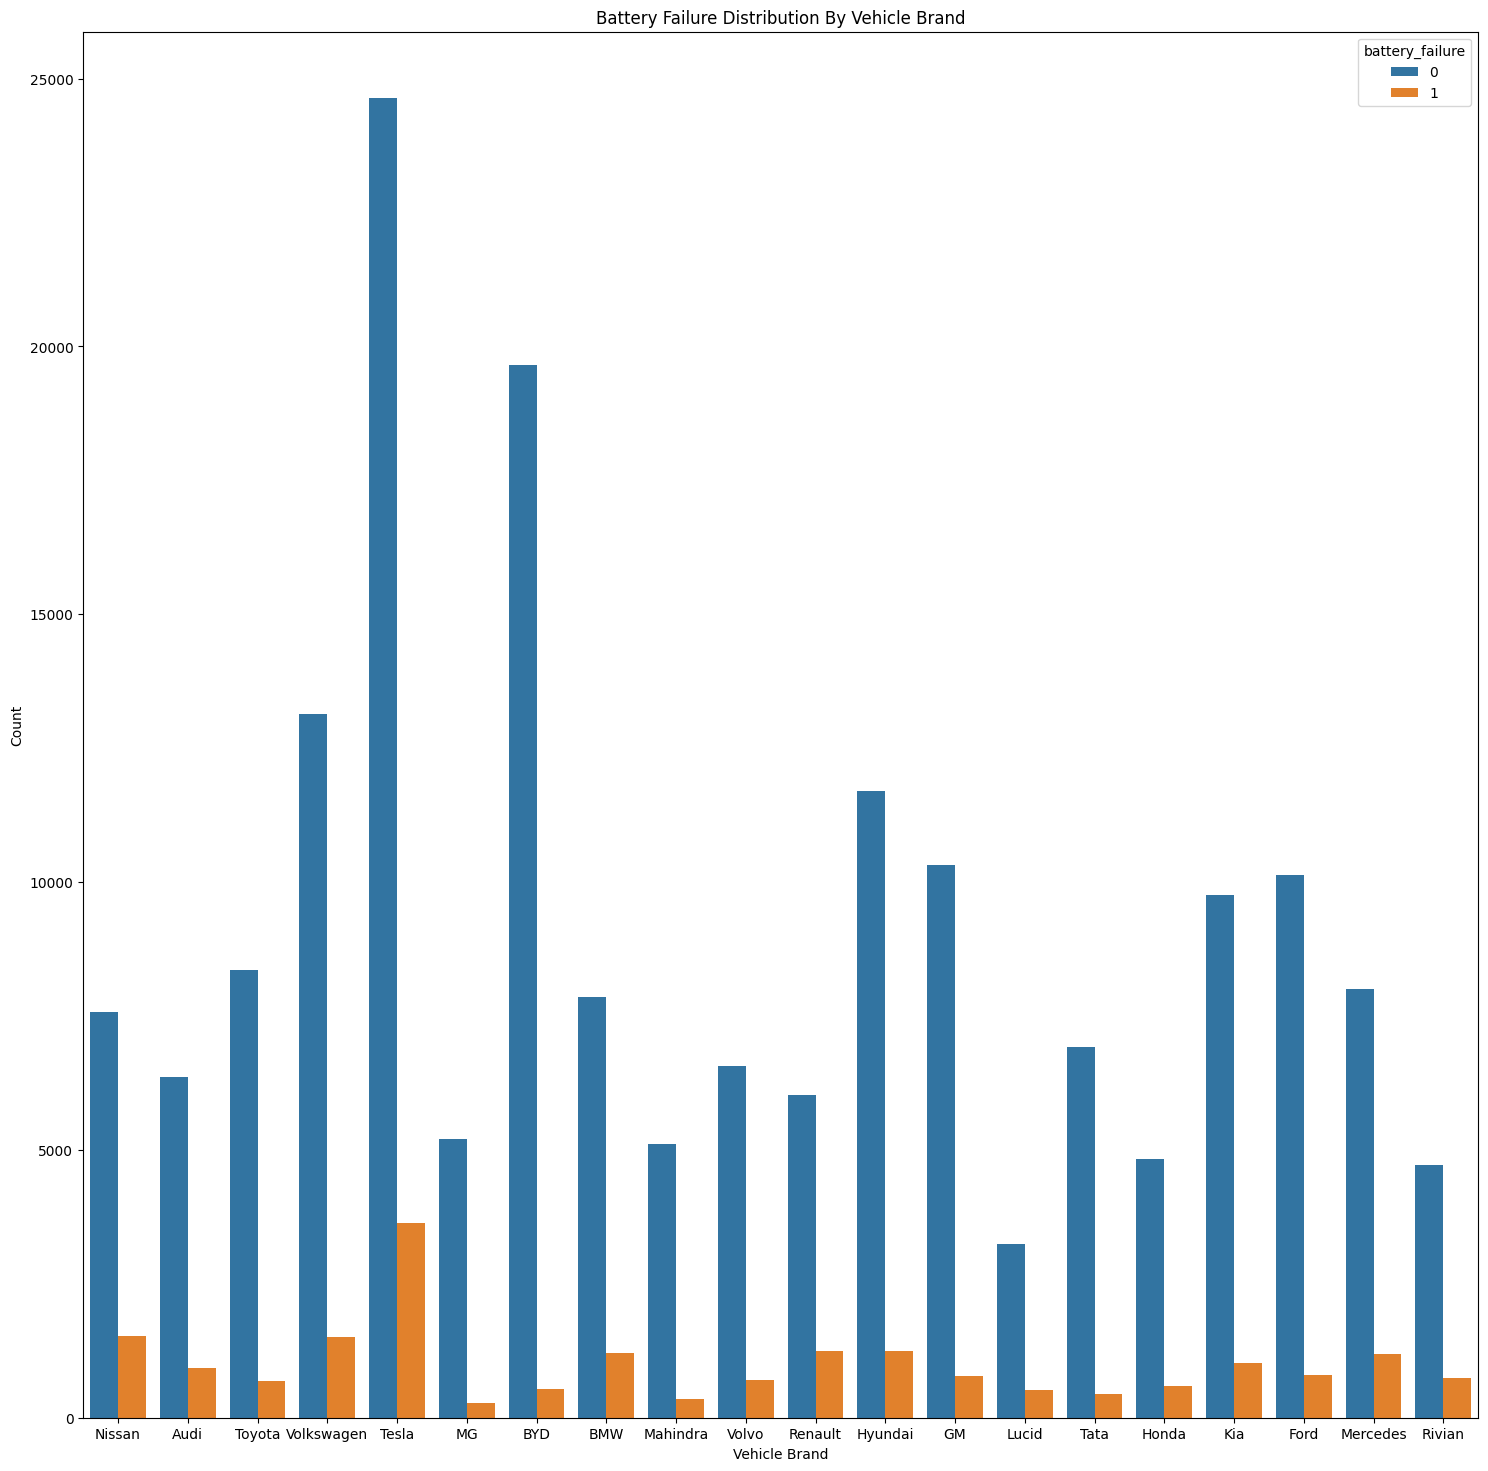

In [17]:
plt.figure(figsize=(18,18))
sns.countplot(data=df,x='vehicle_brand',hue='battery_failure')
plt.title("Battery Failure Distribution By Vehicle Brand")
plt.xlabel('Vehicle Brand')
plt.ylabel('Count')
plt.show()

In [18]:
df['terrain_type'].unique()

array(['Flat', 'Hilly', 'Coastal', 'Desert', 'Mountainous'], dtype=object)

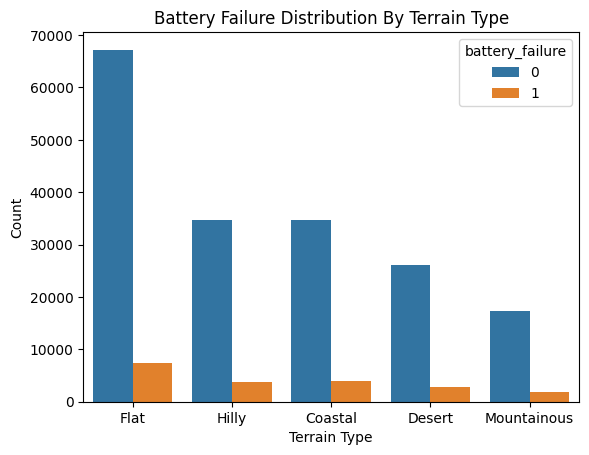

In [19]:
sns.countplot(data=df,x='terrain_type',hue='battery_failure')
plt.title("Battery Failure Distribution By Terrain Type")
plt.xlabel('Terrain Type')
plt.ylabel('Count')
plt.show()

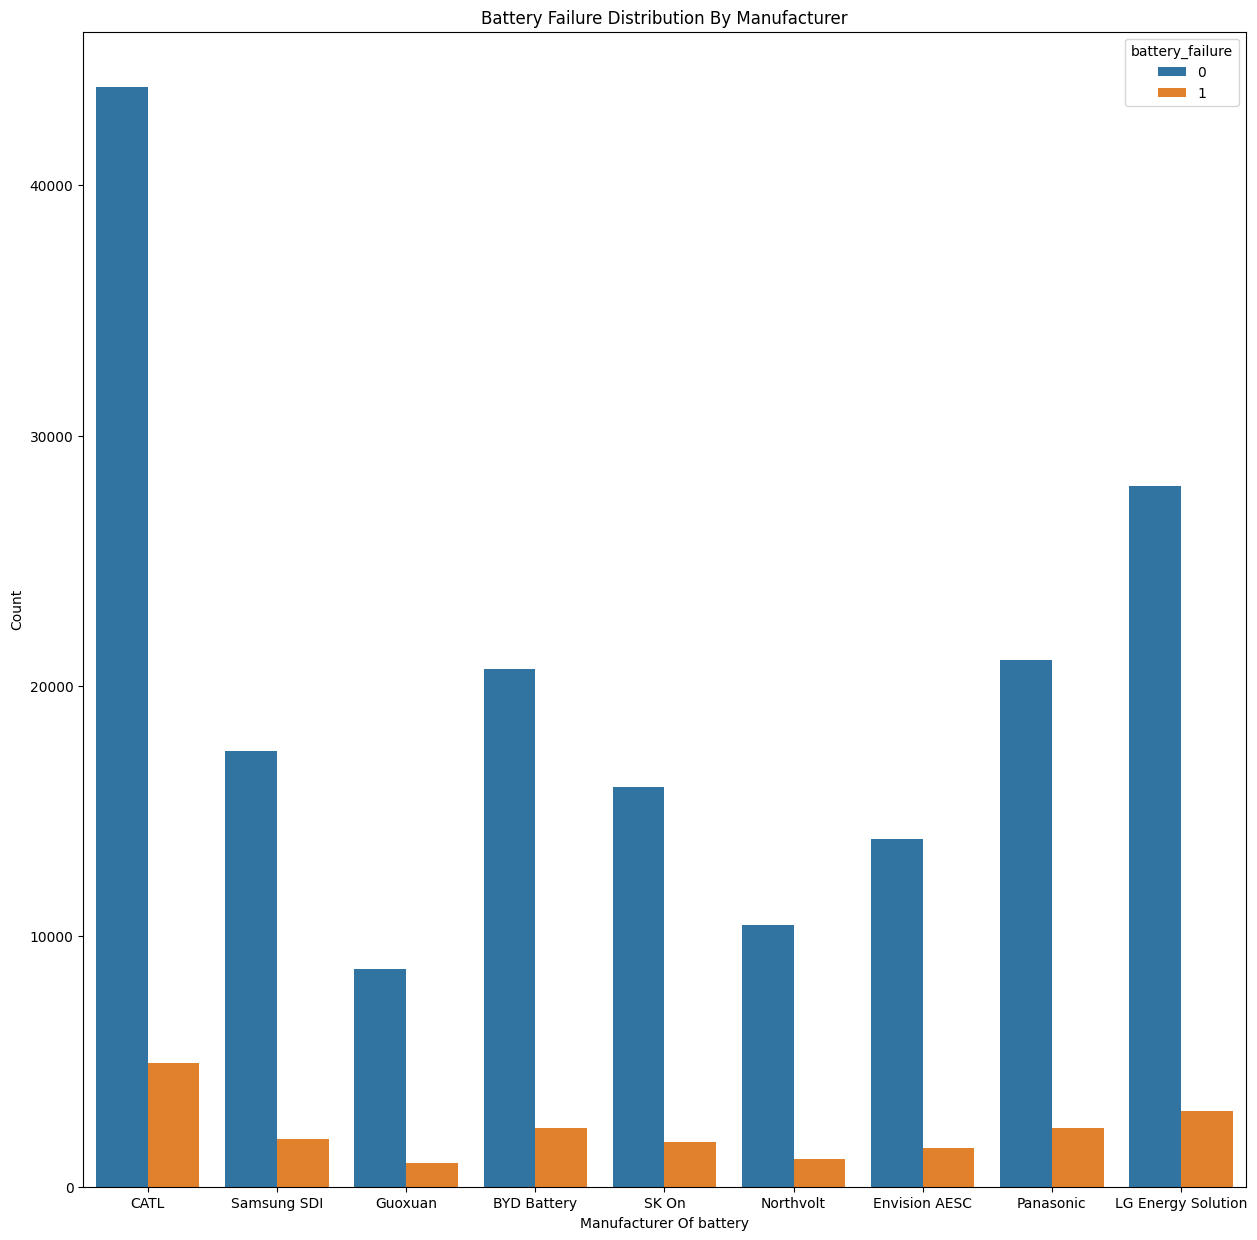

In [20]:
plt.figure(figsize=(15,15))
sns.countplot(data=df,x='battery_manufacturer',hue='battery_failure')
plt.title("Battery Failure Distribution By Manufacturer")
plt.xlabel('Manufacturer Of battery')
plt.ylabel('Count')
plt.show()

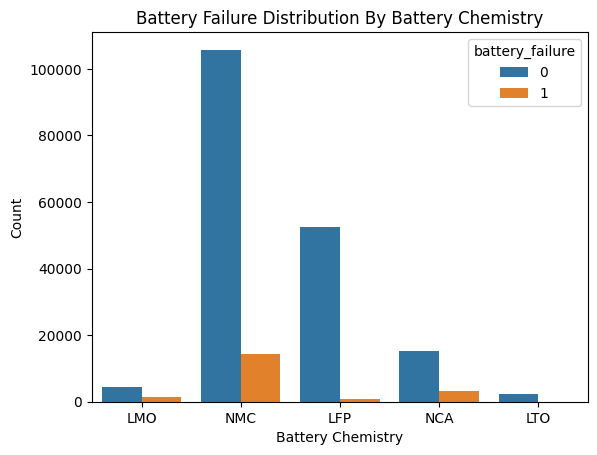

In [21]:
sns.countplot(data=df,x='battery_chemistry',hue='battery_failure')
plt.title("Battery Failure Distribution By Battery Chemistry")
plt.xlabel('Battery Chemistry')
plt.ylabel('Count')
plt.show()

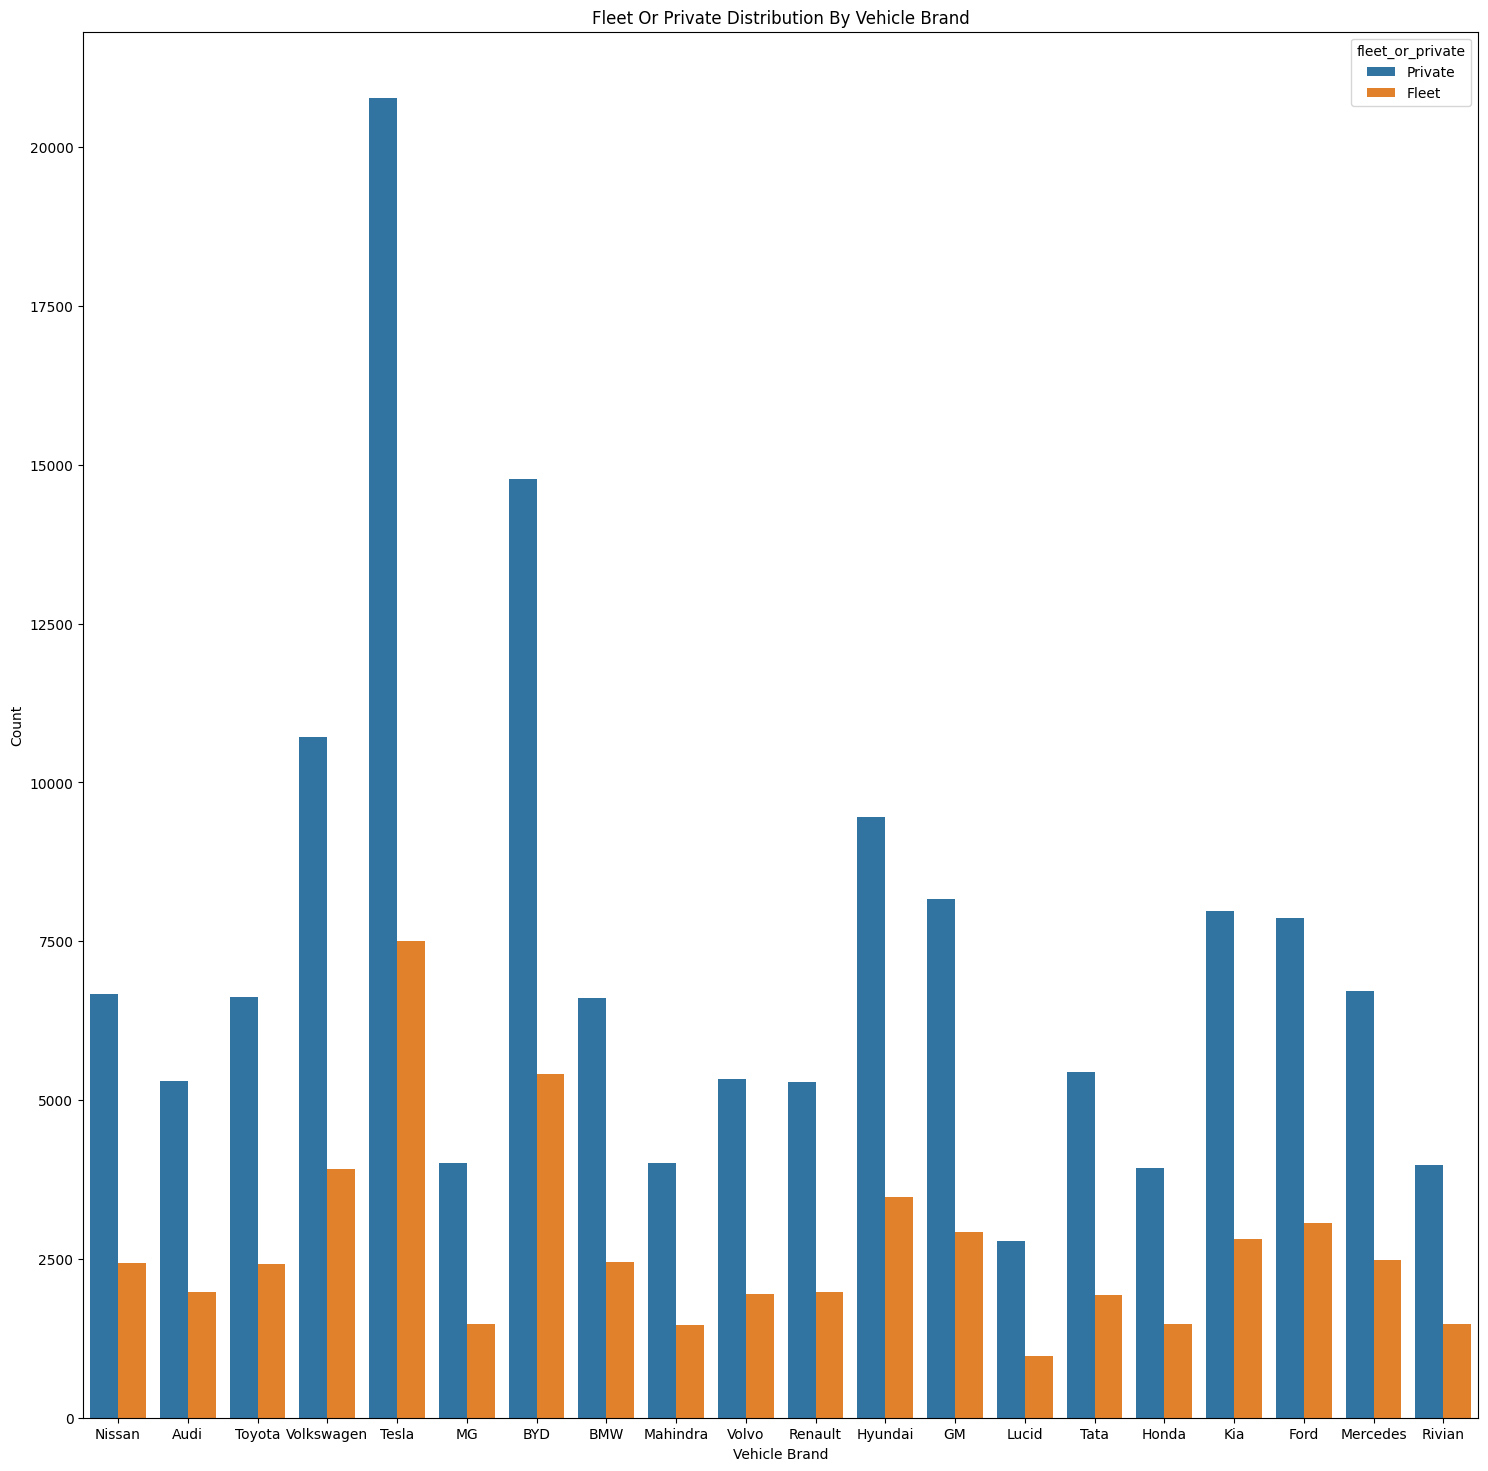

In [22]:
plt.figure(figsize=(18,18))
sns.countplot(data=df,x='vehicle_brand',hue='fleet_or_private')
plt.title("Fleet Or Private Distribution By Vehicle Brand")
plt.xlabel('Vehicle Brand')
plt.ylabel('Count')
plt.show()

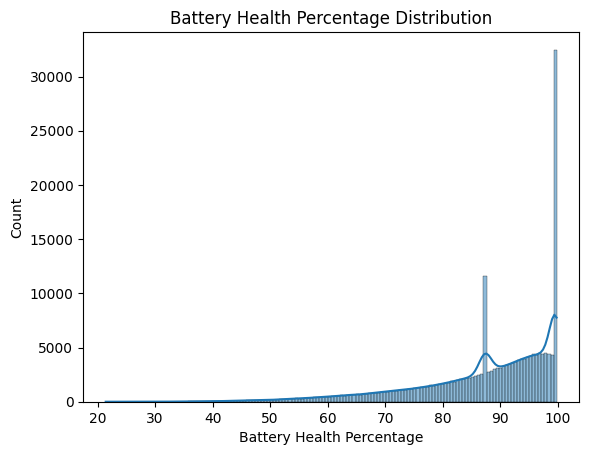

In [23]:
sns.histplot(df['battery_health_percent'],kde=True)
plt.title("Battery Health Percentage Distribution")
plt.xlabel('Battery Health Percentage')
plt.ylabel('Count')
plt.show()

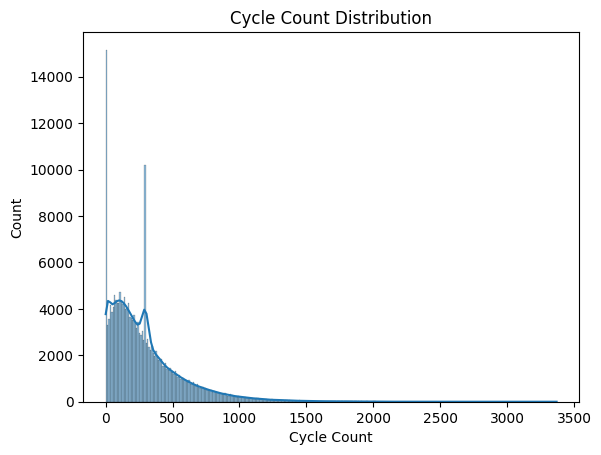

In [24]:
sns.histplot(df['cycle_count'],kde=True)
plt.title("Cycle Count Distribution")
plt.xlabel('Cycle Count')
plt.ylabel('Count')
plt.show()

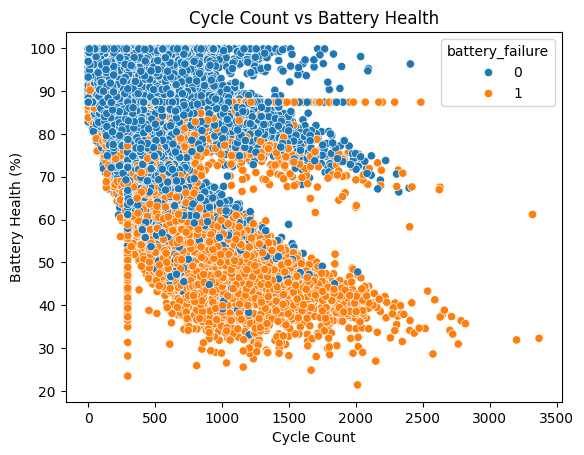

In [25]:
sns.scatterplot(data=df, x='cycle_count', y='battery_health_percent',hue='battery_failure')
plt.xlabel('Cycle Count')
plt.ylabel('Battery Health (%)')
plt.title('Cycle Count vs Battery Health')
plt.show()

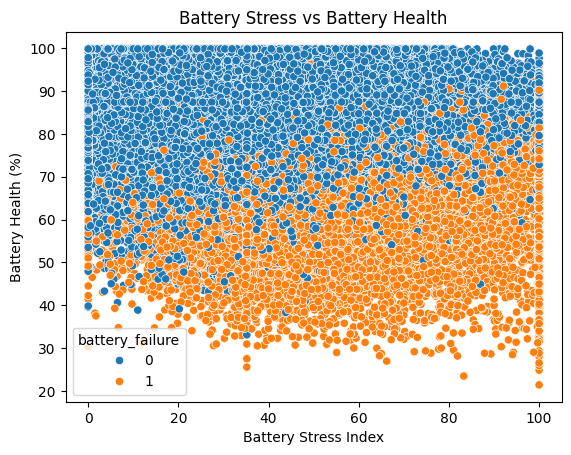

In [26]:
sns.scatterplot(data=df, x='battery_stress_index', y='battery_health_percent',hue='battery_failure')
plt.xlabel('Battery Stress Index')
plt.ylabel('Battery Health (%)')
plt.title('Battery Stress vs Battery Health')
plt.show()

## Convert Categorical Values to Numerical Shows with Labelling

In [27]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = df.select_dtypes('object').columns

for cols in categorical_cols:
  le = LabelEncoder()
  df[cols] = le.fit_transform(df[cols])

  print(f'\n{cols}:')
  for value,numbers in zip(le.classes_, le.transform(le.classes_)):
    print(f"{value} = {numbers}")


vehicle_brand:
Audi = 0
BMW = 1
BYD = 2
Ford = 3
GM = 4
Honda = 5
Hyundai = 6
Kia = 7
Lucid = 8
MG = 9
Mahindra = 10
Mercedes = 11
Nissan = 12
Renault = 13
Rivian = 14
Tata = 15
Tesla = 16
Toyota = 17
Volkswagen = 18
Volvo = 19

vehicle_type:
Crossover = 0
Hatchback = 1
SUV = 2
Sedan = 3
Truck = 4
Van = 5

battery_manufacturer:
BYD Battery = 0
CATL = 1
Envision AESC = 2
Guoxuan = 3
LG Energy Solution = 4
Northvolt = 5
Panasonic = 6
SK On = 7
Samsung SDI = 8

battery_chemistry:
LFP = 0
LMO = 1
LTO = 2
NCA = 3
NMC = 4

drive_type:
AWD = 0
FWD = 1
RWD = 2

fleet_or_private:
Fleet = 0
Private = 1

terrain_type:
Coastal = 0
Desert = 1
Flat = 2
Hilly = 3
Mountainous = 4


In [28]:
df.head(10)

,vehicle_brand,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,cell_voltage_std,pack_voltage,cell_temperature_avg,cell_temperature_max,internal_resistance,charge_efficiency,discharge_efficiency,remaining_capacity,capacity_loss_percent,charging_cycles_last_month,fast_charge_ratio,slow_charge_ratio,average_charge_power_kw,average_charging_time,overnight_charging_ratio,home_charging_ratio,charging_interruptions,overcharge_events,average_speed,average_trip_distance,aggressive_acceleration_score,hard_braking_score,regenerative_braking_usage,highway_driving_ratio,city_driving_ratio,daily_distance,average_ambient_temperature,maximum_temperature,minimum_temperature,humidity,altitude,terrain_type,dust_exposure,last_service_days,cooling_system_health,firmware_updates,previous_faults,maintenance_score,thermal_runaway_risk,voltage_imbalance,temperature_variance,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,12,2,2019.0,1,1,82.54,2,98163.0,6.94,1,250.0,73.61,85.23,26.34,72.93,3.2900,0.01829,934.42,-15.66,-10.04,0.6585,94.63,80.08,60.76,26.39,4.0,0.206,0.797,25.46,212.2,0.543,0.675,0.0,2.0,58.0,38.7,0.0,7.0,69.4,0.352,0.676,50.6,-14.30,-5.90,-21.5,100.00,400.2,2,20.4,159.00,79.30,2.0,0.0,94.8,48.7,15.30,5.28,2.0,3.0,0.0,0.00,53.50,66.0,65.20,0.00,401.0,0
1,0,3,2018.0,8,4,64.17,0,113600.0,7.79,1,256.0,85.77,49.12,44.83,86.71,3.3658,0.01518,841.46,21.67,34.30,0.5206,95.16,94.95,55.04,14.23,3.0,0.417,0.543,55.83,68.5,0.340,0.708,0.0,2.0,30.7,29.4,36.3,33.1,80.7,0.353,0.661,50.6,26.40,44.60,18.8,72.90,702.7,3,15.7,193.00,73.30,3.0,0.0,100.0,48.6,9.42,7.19,0.0,3.0,0.0,51.00,38.80,67.8,46.30,40.90,1094.0,0
2,17,5,2018.0,3,4,90.92,2,242253.0,7.85,0,556.0,72.37,54.85,33.65,72.17,3.4152,0.02000,853.81,16.83,31.37,0.6135,92.21,88.87,65.80,27.63,7.0,0.624,0.379,55.38,120.5,0.416,0.449,0.0,2.0,60.5,40.0,27.6,9.8,71.0,0.374,0.623,101.3,9.50,13.00,2.4,57.80,687.4,2,22.9,193.00,73.80,3.0,1.0,72.2,53.2,18.86,20.75,4.0,1.0,0.0,36.20,66.10,48.6,0.00,6.50,645.0,0
3,18,1,2022.0,1,4,47.35,0,83700.0,6.50,1,353.0,85.11,54.32,37.73,87.30,3.4202,0.01518,739.43,-1.10,6.25,0.4144,94.26,84.69,40.30,14.89,10.0,0.417,0.559,39.19,83.3,0.336,0.760,0.0,0.0,65.6,29.9,12.8,10.1,68.2,0.379,0.599,58.2,-4.20,2.00,-22.5,47.30,752.2,3,59.0,60.00,88.30,0.0,0.0,95.4,53.6,12.99,9.04,0.0,3.0,1.0,23.40,32.50,58.2,50.99,40.95,867.0,0
4,16,0,2015.0,0,4,68.04,1,88784.0,11.13,1,287.0,87.40,62.73,65.29,86.17,3.4556,0.02111,863.90,29.71,31.20,0.5663,96.60,93.78,59.47,12.60,5.0,0.250,0.755,44.07,118.2,0.454,0.586,0.0,0.0,61.6,8.1,61.0,35.4,34.2,0.000,1.000,27.5,17.98,29.80,10.3,30.60,283.6,0,33.9,217.35,48.20,19.0,3.0,100.0,62.1,25.29,10.55,3.0,2.0,1.0,51.20,45.40,51.0,50.99,100.00,1090.0,0
5,9,2,2018.0,8,0,74.97,0,156939.0,8.06,1,483.0,93.80,28.97,40.14,91.07,2.8677,0.01412,716.92,32.04,42.23,0.6265,95.66,96.41,70.32,6.20,6.0,0.529,0.475,59.89,92.5,0.149,0.479,0.0,0.0,60.6,29.4,70.8,40.0,34.9,0.639,0.344,67.1,24.30,28.20,17.8,69.10,124.8,3,32.0,308.00,67.00,7.0,1.0,86.0,23.1,15.12,17.89,0.0,1.0,0.0,49.20,27.70,70.7,49.60,100.00,3258.0,0
6,12,2,2019.0,0,4,76.24,1,185719.0,6.91,0,428.0,76.96,52.06,45.85,80.22,3.4145,0.01689,853.62,26.07,36.90,0.5715,92.88,92.26,73.12,23.04,6.0,0.500,0.489,47.61,134.3,0.200,0.405,2.0,1.0,29.2,32.3,49.6,52.4,54.2,0.610,0.401,96.1,17.20,27.60,9.9,54.99,479.3,3,41.8,162.00,79.80,5.4,0.0,92.2,58.4,13.18,20.93,0.0,5.0,0.0,52.90,29.91,48.8,2.70,83.40,784.0,0
7,12,2,2016.0,1,4,92.36,0,110334.0,10.31,1,195.0,79.89,57.20,55.05,79.21,3.4229,0.02046,855.73,21.67,15.43,0.5637,97.82,86.28,73.79,20.11,2.0,0.760,0.236,64.47,103.8,0.550,0.797,3.0,1.0,47.3,12.9,31.3,28.8,59.2,0.317,0.626,36.8,2.90,27.02,-8.7,43.50,91

## Train and Test Splitting

In [29]:
X = df.drop(columns='battery_failure', axis=1)
y = df['battery_failure']

In [30]:
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size=0.2,random_state=42)

## Using SMOTE Function to Balance the Output Variable

In [31]:

sm = SMOTE()
X_train_sm, y_train_sm = sm.fit_resample(X_train, y_train)

In [32]:

print(y_train.value_counts())
print(y_train_sm.value_counts())

battery_failure
0    144167
1     15833
Name: count, dtype: int64
battery_failure
0    144167
1    144167
Name: count, dtype: int64


## Load the require ML Models

In [33]:

lr = Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression())])
rfc = RandomForestClassifier(n_estimators=200,random_state=42)
dtc = DecisionTreeClassifier(random_state=42)
xgc = XGBClassifier(eval_metric='logloss')

## Logistic Regression

In [34]:
lr.fit(X_train_sm, y_train_sm)

Pipeline(steps=[('scaler', StandardScaler()), ('model', LogisticRegression())])

In [35]:

y_prediction_of_lr = lr.predict(X_test)

accuracy_of_lr = accuracy_score(y_test,y_prediction_of_lr)

print("Accuracy of Logistic Regression:",accuracy_of_lr * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_lr,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE Of Logistic Regression")
print(roc_auc_score(y_test,lr.predict_proba(X_test)[:,1]))

Accuracy of Logistic Regression: 95.0075
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     34511
           1       0.93      0.69      0.79      5489

    accuracy                           0.95     40000
   macro avg       0.94      0.84      0.88     40000
weighted avg       0.95      0.95      0.95     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE Of Logistic Regression
0.9879736327635417


## Decision Tree Classifier

In [36]:

dtc.fit(X_train_sm,y_train_sm)

DecisionTreeClassifier(random_state=42)

In [37]:
y_prediction_of_dtc = dtc.predict(X_test)

accuracy_of_dtc = accuracy_score(y_test,y_prediction_of_dtc)

print("Accuracy of Decision Tree Classifier",accuracy_of_dtc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_dtc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of Decision Tree Classifier")
print(roc_auc_score(y_test,dtc.predict_proba(X_test)[:,1]))

Accuracy of Decision Tree Classifier 92.88499999999999
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.95      0.97      0.96     35166
           1       0.74      0.63      0.68      4834

    accuracy                           0.93     40000
   macro avg       0.85      0.80      0.82     40000
weighted avg       0.92      0.93      0.93     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of Decision Tree Classifier
0.8465697732966734


## Random Forest Classifier

In [38]:
rfc.fit(X_train_sm,y_train_sm)

RandomForestClassifier(n_estimators=200, random_state=42)

In [39]:

y_prediction_of_rfc = rfc.predict(X_test)

accuracy_of_rfc = accuracy_score(y_test,y_prediction_of_rfc)

print("Accuracy Of Random Forest Classifier",accuracy_of_rfc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_rfc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of Random Forest Classifier")
print(roc_auc_score(y_test,rfc.predict_proba(X_test)[:,1]))
     

Accuracy Of Random Forest Classifier 95.6475
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.97      0.98      0.98     35305
           1       0.86      0.75      0.80      4695

    accuracy                           0.96     40000
   macro avg       0.91      0.87      0.89     40000
weighted avg       0.95      0.96      0.96     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of Random Forest Classifier
0.9849754464762528


## XGBoost Classifier

In [40]:
xgc.fit(X_train_sm,y_train_sm)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [41]:
y_prediction_of_xgc = xgc.predict(X_test)

accuracy_of_xgc = accuracy_score(y_test,y_prediction_of_xgc)

print("Accuracy Of XGBoost Classifier",accuracy_of_xgc * 100)
print("-"*50)
print("-"*50)

print("Classification Report")
print(" "*50)

print(classification_report(y_prediction_of_xgc,y_test))

print("-"*50)
print("-"*50)

print("ROC_AUC_SCORE of XGBoost Classifier")
print(roc_auc_score(y_test,xgc.predict_proba(X_test)[:,1]))

Accuracy Of XGBoost Classifier 96.505
--------------------------------------------------
--------------------------------------------------
Classification Report
                                                  
              precision    recall  f1-score   support

           0       0.98      0.98      0.98     36046
           1       0.81      0.84      0.83      3954

    accuracy                           0.97     40000
   macro avg       0.90      0.91      0.90     40000
weighted avg       0.97      0.97      0.97     40000

--------------------------------------------------
--------------------------------------------------
ROC_AUC_SCORE of XGBoost Classifier
0.9882125191923811


## Confusion Matrix

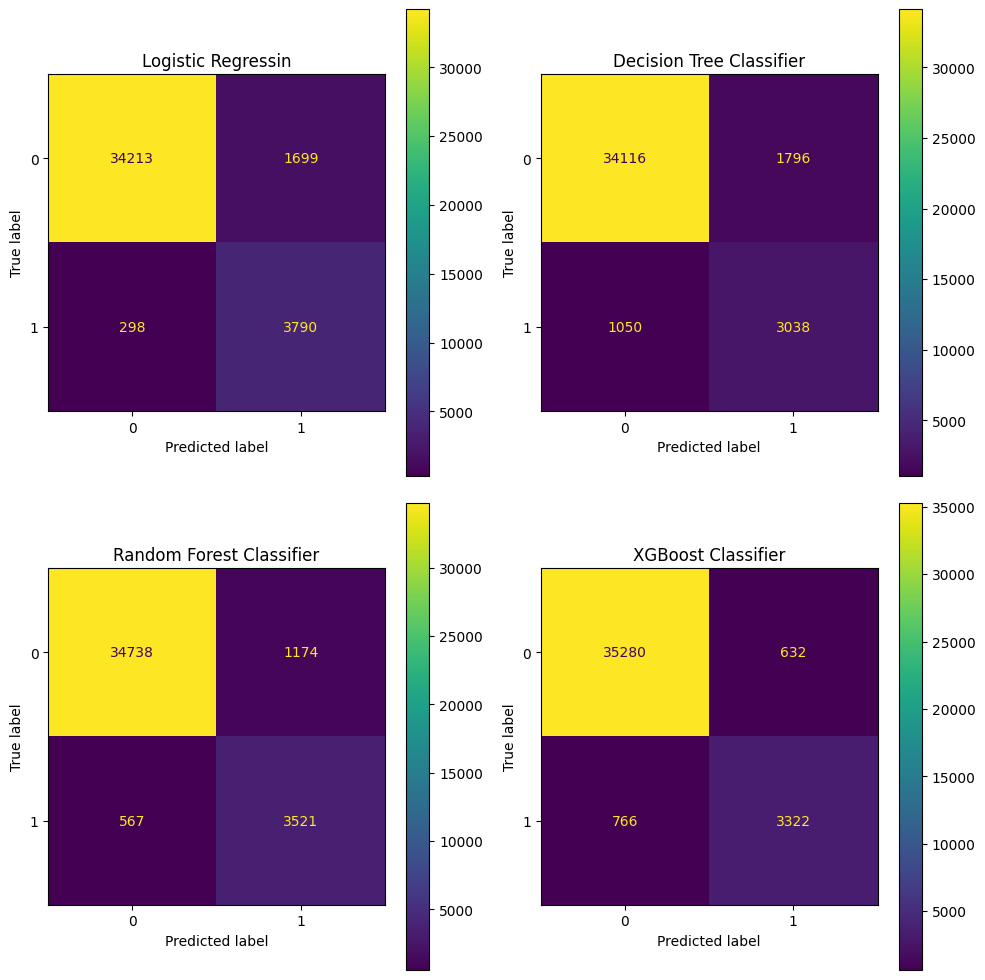

In [42]:

models = [("Logistic Regressin",lr),("Decision Tree Classifier",dtc),("Random Forest Classifier",rfc),("XGBoost Classifier",xgc)]

fig , axes = plt.subplots(2,2, figsize=(10,10))

for ax,(name,model) in zip(axes.ravel(),models):
  ConfusionMatrixDisplay.from_estimator(model,X_test,y_test,ax=ax)
  ax.set_title(name)

plt.tight_layout()
plt.show()
     